In [89]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from kneed import KneeLocator
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.neighbors import NearestNeighbors

import joblib

# 🛍️ Mall Shopper Profiling — Unsupervised Learning

# 1.1  Load & Inspect the Dataset

In [2]:
df = pd.read_csv("Mall_Customers.csv")

display(df.head(10))
print(df.info())
print("\nShape:",df.shape)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

Shape: (200, 5)


In [3]:
# rename columns
df= df.rename(columns={"Annual Income (k$)":"AnnualIncome",
                       "Spending Score (1-100)":"SpendingScore"})
df.head()

,CustomerID,Gender,Age,AnnualIncome,SpendingScore
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
# Missing values
print("Missing values:\n",df.isnull().sum())

Missing values:
 CustomerID       0
Gender           0
Age              0
AnnualIncome     0
SpendingScore    0
dtype: int64


In [5]:
# Report 
print("number of Male and Female:\n",df["Gender"].value_counts())

number of Male and Female:
 Gender
Female    112
Male       88
Name: count, dtype: int64


# 1.2  Univariate Analysis

In [6]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'AnnualIncome', 'SpendingScore'], dtype='object')

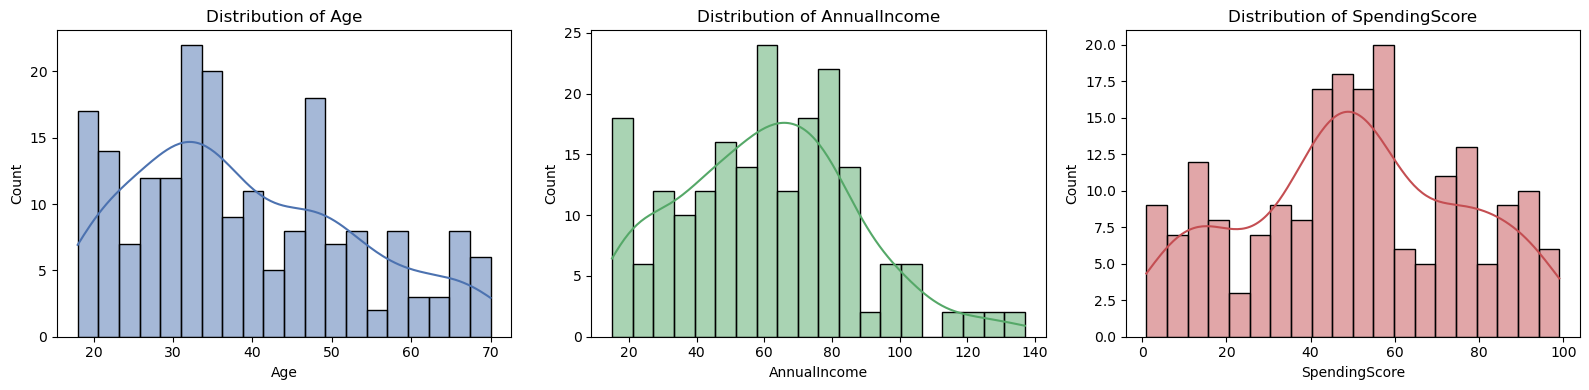

          Age  AnnualIncome  SpendingScore
mean    38.85         60.56          50.20
median  36.00         61.50          50.00
std     13.97         26.26          25.82
skew     0.49          0.32          -0.05


In [17]:
cols= ["Age","AnnualIncome","SpendingScore"]
fig,axes = plt.subplots(1,3,figsize=(16,4))
for ax, col, colr in zip(axes, cols, ["#4C72B0", "#55A868", "#C44E52"]):
    sns.histplot(df[col], bins=20, kde=True, color=colr, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()
print(df[cols].agg(["mean","median","std","skew"]).round(2))

- Age : mildly right skewed,most shoppers are 30-50, with a tail to 70.
- Annuallncome : close to symmetric with slight right t skew
- Spending Score : almost perfectly symmetric

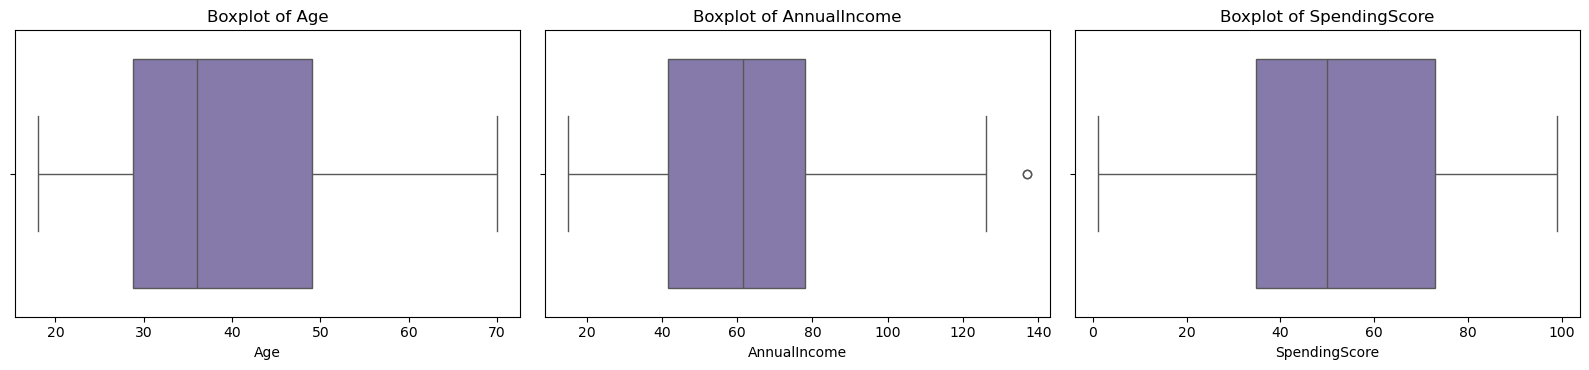

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, cols):
    sns.boxplot(x=df[col], color="#8172B2", ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

- Age and Spending Score show no outliers 
- Annuallincome shows just outliers at 140 ,thay are gnuine customers.

C:\Users\MAYUR MAKVANA\AppData\Local\Temp\ipykernel_24104\4035730601.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="Gender", palette=["#DD8452", "#4C72B0"], order=["Female", "Male"])


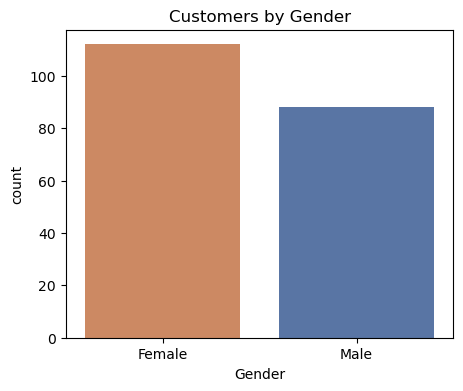

In [14]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="Gender", palette=["#DD8452", "#4C72B0"], order=["Female", "Male"])
plt.title("Customers by Gender");
plt.show()

- gender balance : the dataset is reasonably balanced - slightly female heavy

# 1.3  Bivariate Analysis

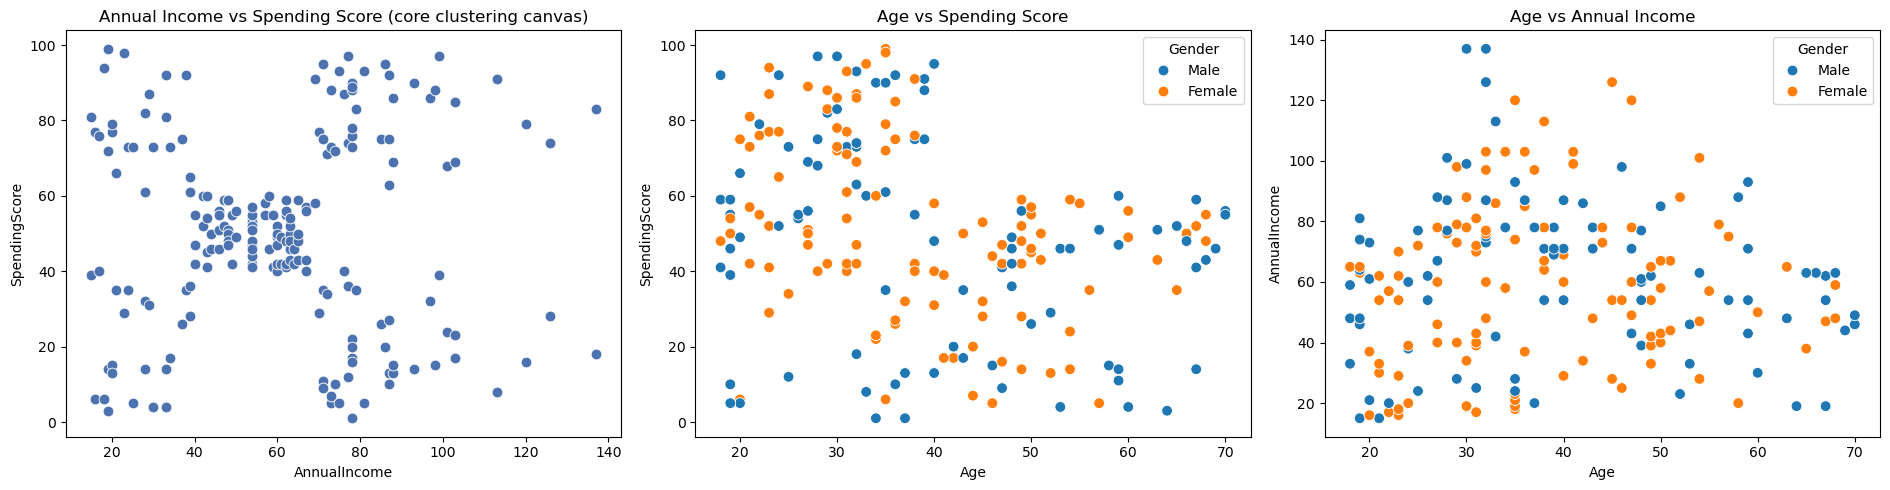

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.scatterplot(data=df, x="AnnualIncome", y="SpendingScore", color="#4C72B0", s=60, ax=axes[0])
axes[0].set_title("Annual Income vs Spending Score (core clustering canvas)")

sns.scatterplot(data=df, x="Age", y="SpendingScore", hue="Gender", s=60, ax=axes[1])
axes[1].set_title("Age vs Spending Score")

sns.scatterplot(data=df, x="Age", y="AnnualIncome", hue="Gender", s=60, ax=axes[2])
axes[2].set_title("Age vs Annual Income")
plt.tight_layout(); 
plt.show()

                 Age  AnnualIncome  SpendingScore
Age            1.000        -0.012         -0.327
AnnualIncome  -0.012         1.000          0.010
SpendingScore -0.327         0.010          1.000


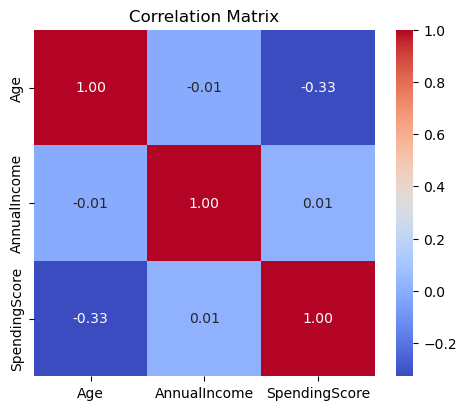

In [20]:
corr = df[["Age", "AnnualIncome", "SpendingScore"]].corr()
print(corr.round(3))
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# 1.4  Gender-Wise Summary

          Age  AnnualIncome  SpendingScore
Gender                                    
Female  38.10         59.25          51.53
Male    39.81         62.23          48.51


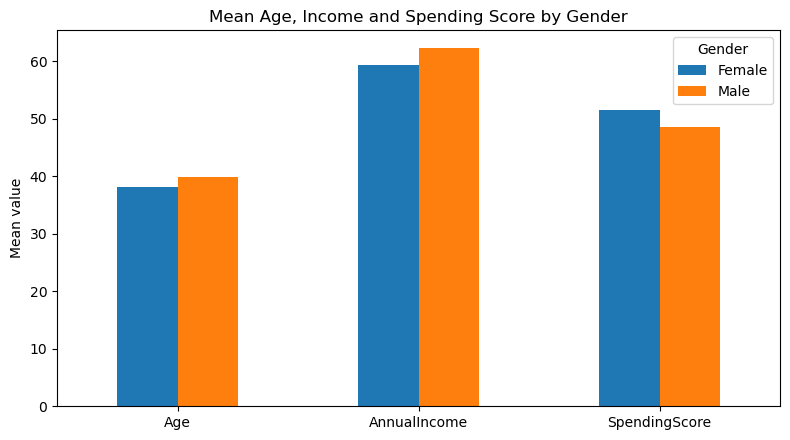

In [25]:
gender_summary = df.groupby("Gender")[cols].mean().round(2)
print(gender_summary)
gender_summary.T.plot(kind="bar", figsize=(8, 4.5),rot=0)
plt.title("Mean Age, Income and Spending Score by Gender")
plt.ylabel("Mean value")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

- summary : 
    - Female score slightly higher on spending,annual earning slightly less and Age younger.
    - all gaps are small.
    - so geander al;one is a weak segmentation income x spending matters far more

- Key insight: (income vs spending)
    - the scatter plot shows five visuallu distinct groups:
        1. Top-right : high income and high spending
        2. Bottom-right : high income but very low spending
        3. Top-left : low income but high spending
        4. Bottom-left : low income and low spending
        5. centre : the center part

# step 2: Feature Engineering & Preprocessing
# 2.1  Encode Categorical Feature

In [28]:
df["Gender_enc"] = df["Gender"].map({"Female":0,"Male":1})
df[["Gender","Gender_enc"]].drop_duplicates()

,Gender,Gender_enc
0,Male,1
2,Female,0


# 2.2  Engineer New Features

In [31]:
df["IncomeGroup"] = pd.qcut(df["AnnualIncome"],q=3,labels=["Low","Medium","High"])

df["AgeGroups"] = pd.cut(df["Age"],bins=[17,25,40,55,100],labels=["young","Adult","Middle-Aged","Senior"])

df["SpendingCategory"] = pd.cut(df["SpendingScore"],bins=[0,33,66,100],labels=["Low","Medium","High"])

for col in ["IncomeGroup", "AgeGroups", "SpendingCategory"]:
    print(f"--  {col} --")
    print(df[col].value_counts())
    print()

--  IncomeGroup --
IncomeGroup
Low       70
High      66
Medium    64
Name: count, dtype: int64

--  AgeGroups --
AgeGroups
Adult          84
Middle-Aged    49
young          38
Senior         29
Name: count, dtype: int64

--  SpendingCategory --
SpendingCategory
Medium    94
High      57
Low       49
Name: count, dtype: int64



- Bins :
    - Income group is almost perfectly balanced because equal-frequency
    - Age Group is imbalanced
    - Spending Category is bell shaped because "Medium"

# 2.3  Select Features for Clustering

In [32]:
feat_2d = ["AnnualIncome", "SpendingScore"]
feat_5d = ["Age", "AnnualIncome", "SpendingScore", "Gender_enc"]
X_2d = df[feat_2d].copy()
X_5d = df[feat_5d].copy()

# 2.4  Scale the Features

In [34]:
scaler_2d = StandardScaler().fit(X_2d)
scaler_5d = StandardScaler().fit(X_5d)
X_2d_scaled = scaler_2d.transform(X_2d)
X_5d_scaled = scaler_5d.transform(X_5d)


print("X_2d_scaled  mean:", X_2d_scaled.mean(axis=0).round(6), " std:", X_2d_scaled.std(axis=0).round(6))
print("X_5d_scaled  mean:", X_5d_scaled.mean(axis=0).round(6), " std:", X_5d_scaled.std(axis=0).round(6))

X_2d_scaled  mean: [-0. -0.]  std: [1. 1.]
X_5d_scaled  mean: [-0. -0. -0.  0.]  std: [1. 1. 1. 1.]


# Step 3: K-Means Clustering
# 3.1  Elbow Method — Find Optimal k  (on X_2d_scaled)

C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312

 k  Inertia  Silhouette
 2   269.69      0.3213
 3   157.70      0.4666
 4   108.92      0.4939
 5    65.57      0.5547
 6    55.06      0.5399
 7    44.86      0.5281
 8    37.23      0.4552
 9    32.39      0.4571
10    29.98      0.4432

Elbow k = 5 | best-Silhouette k = 5


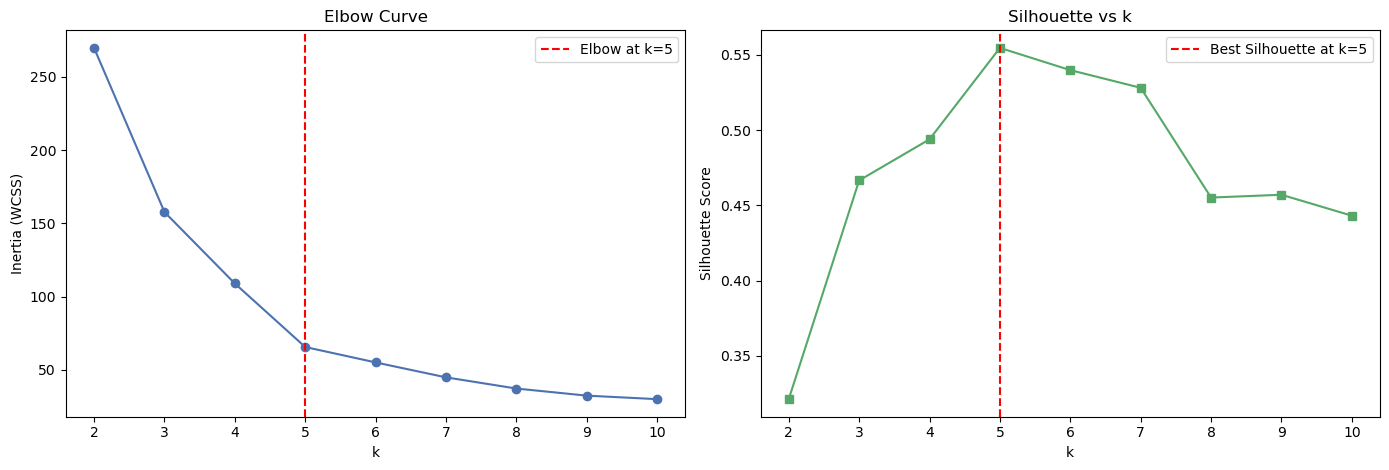

Chosen k_optimal = 5


In [40]:
ks = list(range(2,11))
inertias, sils = [],[]
for k in ks:
    km = KMeans(n_clusters=k,init="k-means++",n_init=10,random_state=42).fit(X_2d_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_2d_scaled,km.labels_))

res = pd.DataFrame({"k": ks,"Inertia":np.round(inertias,2),"Silhouette":np.round(sils,4)})
print(res.to_string(index=False))

k_elbow = KneeLocator(ks,inertias,curve="convex",direction="decreasing").elbow
k_sil = ks[int(np.argmax(sils))]
print(f"\nElbow k = {k_elbow} | best-Silhouette k = {k_sil}")
k_optimal = k_sil

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(ks, inertias, "o-", color="#4C72B0")
axes[0].axvline(k_elbow, color="red", ls="--", label=f"Elbow at k={k_elbow}")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_title("Elbow Curve")
axes[0].legend()

axes[1].plot(ks, sils, "s-", color="#55A868")
axes[1].axvline(k_sil, color="red", ls="--", label=f"Best Silhouette at k={k_sil}")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette vs k")
axes[1].legend()
plt.tight_layout()
plt.show()
print("Chosen k_optimal =", k_optimal)


- choice k=5:
    - inertia drops sharply from 157.7 to 108.9 to 65.6 and then flattens 55.1 so k=5
    - the silhouette score peaks at k=5
    - so ,k=5

# 3.2  Train Final K-Means Model

In [44]:
kmeans_2d = KMeans(n_clusters=k_optimal,init="k-means++",n_init=20,max_iter=500,random_state=42).fit(X_2d_scaled)
df["KMeans_Cluster"] = kmeans_2d.labels_

kmeans_5d = KMeans(n_clusters=k_optimal,init="k-means++",n_init=20,max_iter=500,random_state=42).fit(X_5d_scaled)
df["KMeans_5d_Cluster"] = kmeans_5d.labels_
sil_2d = silhouette_score(X_2d_scaled, df["KMeans_Cluster"])
sil_5d = silhouette_score(X_5d_scaled, df["KMeans_5d_Cluster"])

cmp = pd.DataFrame({
    "Feature set": ["2D (Income, Score)", "Multi-D (Age, Income, Score, Gender)"],
    "Silhouette": [round(sil_2d, 4), round(sil_5d, 4)]
})
print(cmp.to_string(index=False))
print("\nBetter-separated clusters:", "2D" if sil_2d > sil_5d else "5D")

                         Feature set  Silhouette
                  2D (Income, Score)      0.5547
Multi-D (Age, Income, Score, Gender)      0.3144

Better-separated clusters: 2D


C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


- 2d vs 5d :
    - the 2d feature set give clearly better-separated clusters

# 3.3  Visualise K-Means Clusters

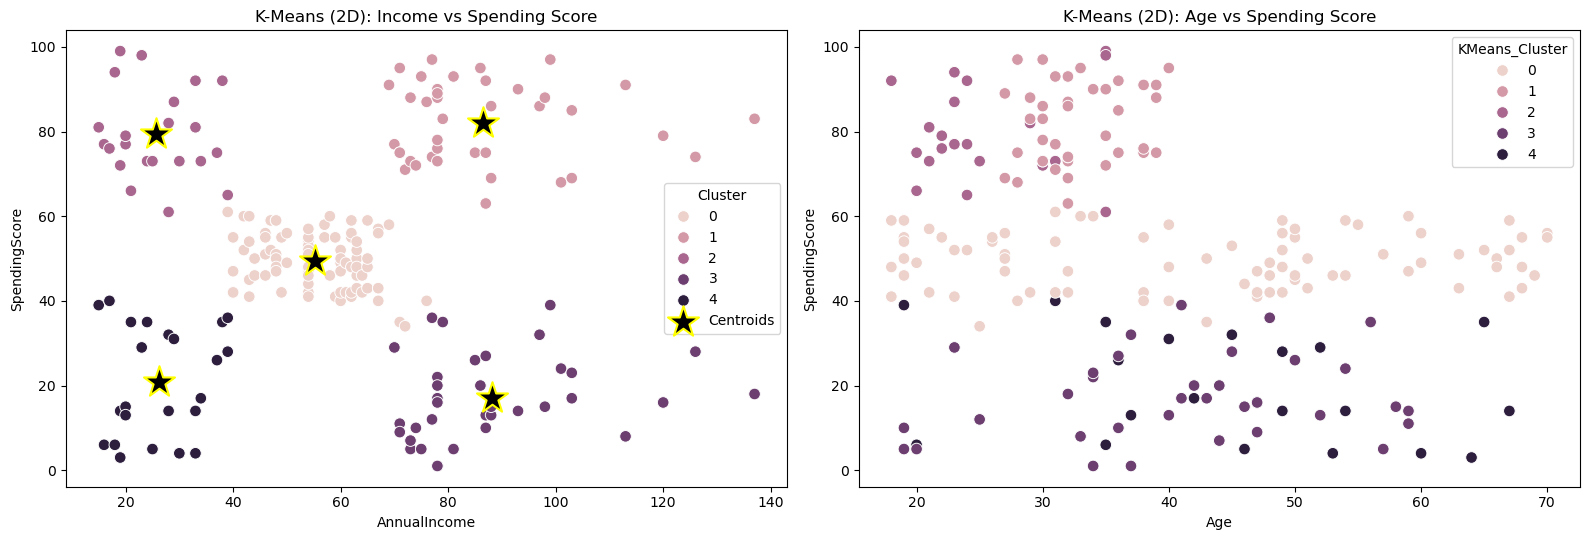

In [48]:
centers_orig = scaler_2d.inverse_transform(kmeans_2d.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(data=df, x="AnnualIncome", y="SpendingScore", hue="KMeans_Cluster", s=70, ax=axes[0], legend="full")
axes[0].scatter(centers_orig[:, 0], centers_orig[:, 1], marker="*", s=550, c="black",
                edgecolor="yellow", linewidth=1.5, label="Centroids")
axes[0].set_title("K-Means (2D): Income vs Spending Score")
axes[0].legend(title="Cluster")
sns.scatterplot(data=df, x="Age", y="SpendingScore", hue="KMeans_Cluster",s=70, ax=axes[1], legend="full")
axes[1].set_title("K-Means (2D): Age vs Spending Score")
plt.tight_layout()
plt.show()

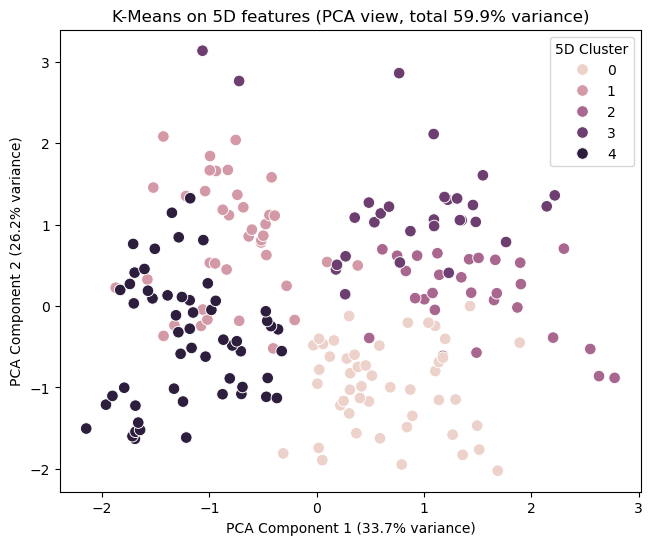

In [51]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_5d_scaled)
ev = pca.explained_variance_ratio_ * 100
plt.figure(figsize=(7.5, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["KMeans_5d_Cluster"], s=70)
plt.xlabel(f"PCA Component 1 ({ev[0]:.1f}% variance)")
plt.ylabel(f"PCA Component 2 ({ev[1]:.1f}% variance)")
plt.title(f"K-Means on 5D features (PCA view, total {ev.sum():.1f}% variance)")
plt.legend(title="5D Cluster")
plt.show()

# 3.4  Profile the K-Means Clusters

In [54]:
def persona_from_profile(income, spending):
    """Rule-based retail persona from a cluster's mean income (k$) and spending score."""
    if income >= 70:
        return "Big Spenders" if spending >= 50 else "Careful Spenders"
    if income <= 40:
        return "Young Aspirers" if spending >= 50 else "Budget Shoppers"
    return "Mainstream Shoppers"


def profile_clusters(frame, label_col, exclude_noise=True):
    """Unscaled mean Age / Income / Score per cluster, sorted by SpendingScore (desc)."""
    d = frame[frame[label_col] != -1] if exclude_noise else frame
    prof = d.groupby(label_col).agg(Count=("Age", "size"), Age=("Age", "mean"),
                                     AnnualIncome=("AnnualIncome", "mean"),
                                     SpendingScore=("SpendingScore", "mean")).round(1)
    prof["Persona"] = [persona_from_profile(r.AnnualIncome, r.SpendingScore) for r in prof.itertuples()]
    return prof.sort_values("SpendingScore", ascending=False)

def gender_split(frame, label_col, exclude_noise=True):
    d = frame[frame[label_col] != -1] if exclude_noise else frame
    return (pd.crosstab(d[label_col], d["Gender"], normalize="index") * 100).round(1).add_prefix("%_")

In [57]:
km_profile = profile_clusters(df, "KMeans_Cluster")
print("K-Means (2D) cluster profile - sorted by SpendingScore (desc)")
display(km_profile)
print("Gender split per cluster (%)")
display(gender_split(df, "KMeans_Cluster"))

km_persona = km_profile["Persona"].to_dict()
df["KMeans_Persona"] = df["KMeans_Cluster"].map(km_persona)
df["KMeans_Persona"].value_counts()

K-Means (2D) cluster profile - sorted by SpendingScore (desc)


,Count,Age,AnnualIncome,SpendingScore,Persona
KMeans_Cluster,,,,,
1,39,32.7,86.5,82.1,Big Spenders
2,22,25.3,25.7,79.4,Young Aspirers
0,81,42.7,55.3,49.5,Mainstream Shoppers
4,23,45.2,26.3,20.9,Budget Shoppers
3,35,41.1,88.2,17.1,Careful Spenders


Gender split per cluster (%)


Gender,%_Female,%_Male
KMeans_Cluster,,
0,59.3,40.7
1,53.8,46.2
2,59.1,40.9
3,45.7,54.3
4,60.9,39.1


KMeans_Persona
Mainstream Shoppers    81
Big Spenders           39
Careful Spenders       35
Budget Shoppers        23
Young Aspirers         22
Name: count, dtype: int64

### Retail Personas (K-Means, k = 5)

**1. Big Spenders**
- Income: $86.5k
- Spending Score: 82.1
- Age: 32.7
- Customers: 39
- Why: High income and high spending. Premium-brand shoppers.

**2. Young Aspirers**
- Income: $25.7k
- Spending Score: 79.4
- Age: 25.3
- Customers: 22
- Why: Lowest income but near-top spending. Young, fashion- and trend-driven shoppers.

**3. Mainstream Shoppers**
- Income: $55.3k
- Spending Score: 49.5
- Age: 42.7
- Customers: 81
- Why: Average income and spending. Largest customer segment (40%).

**4. Budget Shoppers**
- Income: $26.3k
- Spending Score: 20.9
- Age: 45.2
- Customers: 23
- Why: Low income and low spending. Value-conscious and deal-seeking shoppers.

**5. Careful Spenders**
- Income: $88.2k
- Spending Score: 17.1
- Age: 41.1
- Customers: 35
- Why: High income but low spending. An untapped business opportunity.

**Gender Insights:**
Four clusters are approximately 54–61% female. Only Careful Spenders is slightly male-leaning (54% male). Therefore, gender is not a strong differentiating factor for these customer segments.

# Step 4: Agglomerative Hierarchical Clustering
# 4.1  Dendrogram Analysis  (on X_2d_scaled)

Largest gap: 4.35 -> 9.45  (gap = 5.10)
Cut threshold = 6.90  ->  5 clusters


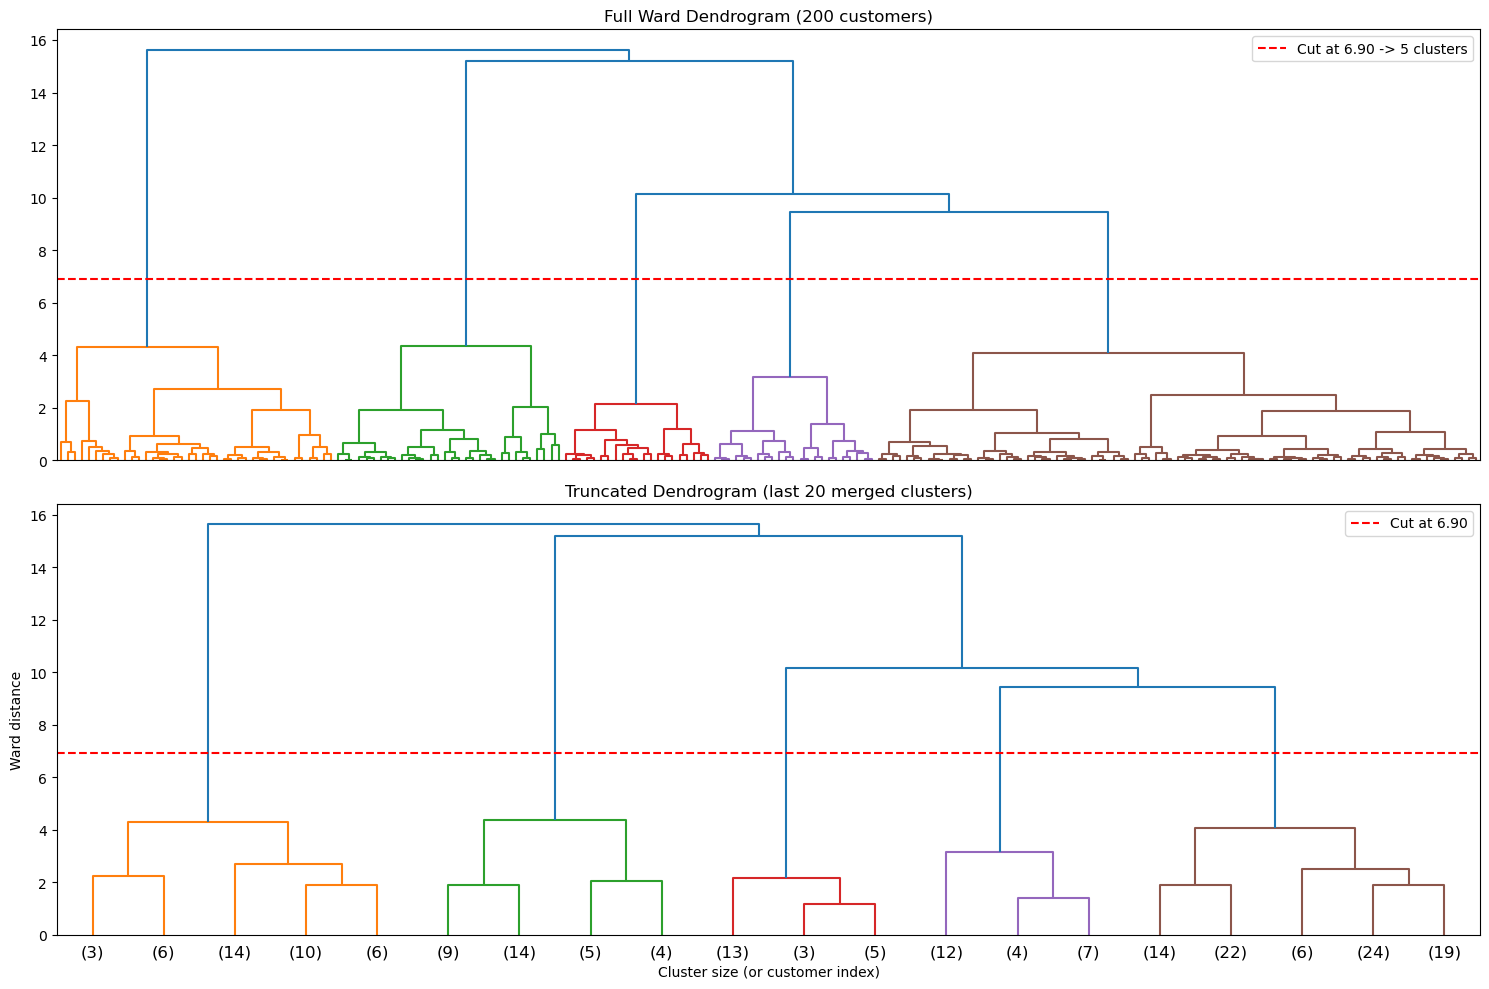

In [60]:
Z=linkage(X_2d_scaled,method="ward")
merge_dist = Z[:,2]

gaps = np.diff(merge_dist)
gi = int(np.argmax(gaps))
cut_height = (merge_dist[gi] + merge_dist[gi + 1]) / 2
n_chosen = int((merge_dist > cut_height).sum() + 1)
print(f"Largest gap: {merge_dist[gi]:.2f} -> {merge_dist[gi+1]:.2f}  (gap = {gaps[gi]:.2f})")
print(f"Cut threshold = {cut_height:.2f}  ->  {n_chosen} clusters")

fig, axes = plt.subplots(2, 1, figsize=(15, 10))
dendrogram(Z, ax=axes[0], no_labels=True, color_threshold=cut_height)
axes[0].axhline(cut_height, color="red", ls="--", label=f"Cut at {cut_height:.2f} -> {n_chosen} clusters")
axes[0].set_title("Full Ward Dendrogram (200 customers)")
axes[0].legend()

dendrogram(Z, ax=axes[1], truncate_mode="lastp", p=20, show_leaf_counts=True, color_threshold=cut_height)
axes[1].axhline(cut_height, color="red", ls="--", label=f"Cut at {cut_height:.2f}")
axes[1].set_title("Truncated Dendrogram (last 20 merged clusters)")
axes[1].set_xlabel("Cluster size (or customer index)")
axes[1].set_ylabel("Ward distance")
axes[1].legend()
plt.tight_layout()
plt.show()

- cut: 
    - the longest vertical line that no horizontal line crosses lies between merge hegight 4.35 and 9.45
    - gives 5 clusters

In [61]:
def internal_metrics(X, labels):
    """Silhouette / Davies-Bouldin / Calinski-Harabasz on non-noise points."""
    m = labels != -1
    return (silhouette_score(X[m], labels[m]), davies_bouldin_score(X[m], labels[m]),
            calinski_harabasz_score(X[m], labels[m]))


# 4.2  Train Agglomerative Model

In [62]:
rows, agg_models = [], {}
for link in ["ward", "complete", "average"]:
    lab = AgglomerativeClustering(n_clusters=n_chosen, linkage=link).fit_predict(X_2d_scaled)
    agg_models[link] = lab
    rows.append({"Linkage": link, "Silhouette": round(silhouette_score(X_2d_scaled,lab), 4)})
link_cmp = pd.DataFrame(rows).set_index("Linkage")
display(link_cmp)

best_link = link_cmp["Silhouette"].idxmax()
print("Best linkage by Silhouette:", best_link)
df["Agg_Cluster"] = agg_models[best_link]

,Silhouette
Linkage,
ward,0.5538
complete,0.5531
average,0.4794


Best linkage by Silhouette: ward


# 4.3  Visualise & Profile Hierarchical Clusters

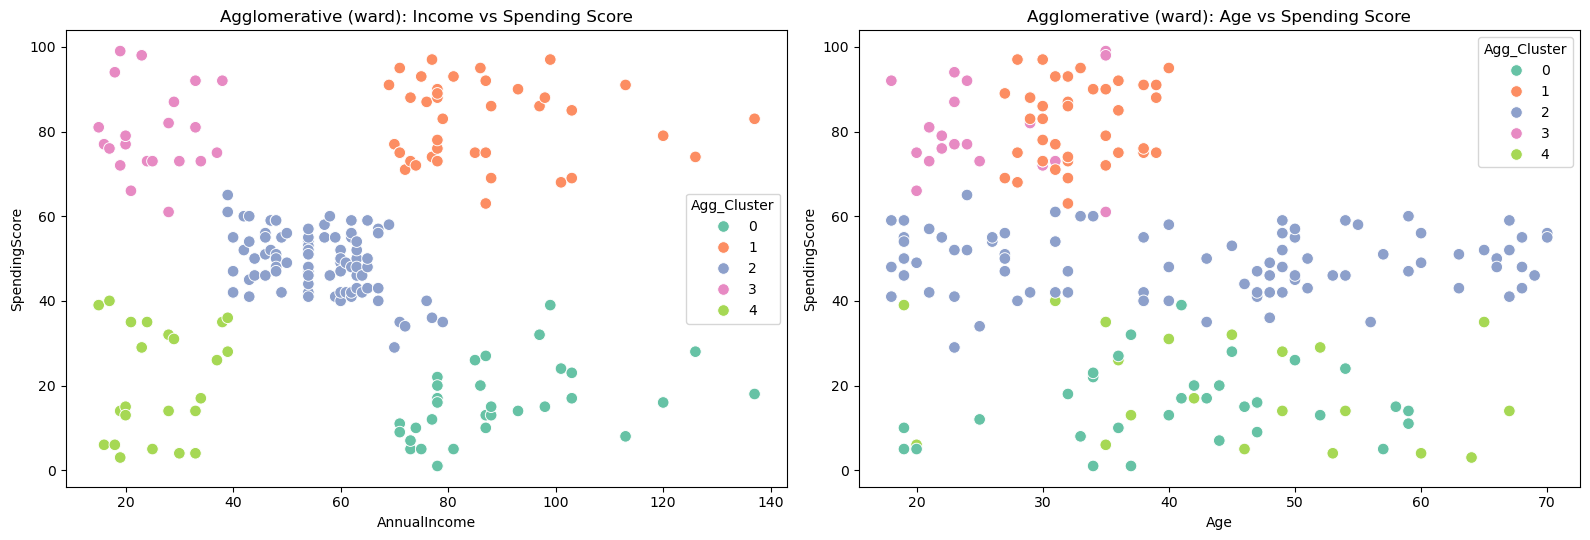

Agglomerative cluster profile (sorted by SpendingScore desc)


,Count,Age,AnnualIncome,SpendingScore,Persona
Agg_Cluster,,,,,
1,39,32.7,86.5,82.1,Big Spenders
3,21,25.3,25.1,80.0,Young Aspirers
2,85,42.5,55.8,49.1,Mainstream Shoppers
4,23,45.2,26.3,20.9,Budget Shoppers
0,32,41.0,89.4,15.6,Careful Spenders


In [65]:
palette_a = sns.color_palette("Set2", n_chosen)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(data=df, x="AnnualIncome", y="SpendingScore", hue="Agg_Cluster",
                palette=palette_a, s=70, ax=axes[0], legend="full")
axes[0].set_title(f"Agglomerative ({best_link}): Income vs Spending Score")
sns.scatterplot(data=df, x="Age", y="SpendingScore", hue="Agg_Cluster",
                palette=palette_a, s=70, ax=axes[1], legend="full")
axes[1].set_title(f"Agglomerative ({best_link}): Age vs Spending Score")
plt.tight_layout()
plt.show()

agg_profile = profile_clusters(df, "Agg_Cluster")
print("Agglomerative cluster profile (sorted by SpendingScore desc)")
display(agg_profile)
df["Agg_Persona"] = df["Agg_Cluster"].map(agg_profile["Persona"].to_dict())


# Step 5: DBSCAN Clustering
# 5.1  Tune Epsilon (ε) Using k-NN Distance Plot  (on X_2d_scaled)

Knee at index 172: eps = 0.368


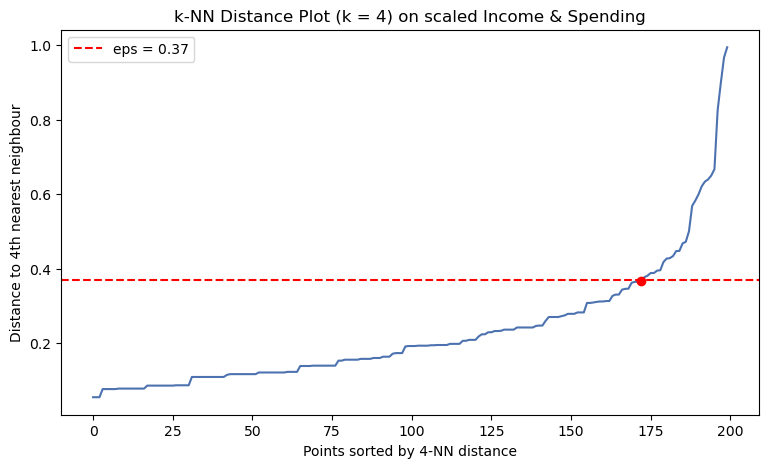

Chosen eps = 0.37


In [69]:
nn = NearestNeighbors(n_neighbors=4).fit(X_2d_scaled)
distances, _ = nn.kneighbors(X_2d_scaled)
k_dist = np.sort(distances[:, -1])

# knee of the sorted k-distance curve (curve bends upward -> convex, increasing)
idx = np.arange(len(k_dist))
elbow_idx = KneeLocator(idx, k_dist, curve="convex", direction="increasing").knee
eps_knee = float(k_dist[elbow_idx])
print(f"Knee at index {elbow_idx}: eps = {eps_knee:.3f}")

optimal_eps = round(eps_knee, 2)
plt.figure(figsize=(9, 5))
plt.plot(k_dist, color="#4C72B0")
plt.axhline(optimal_eps, color="red", ls="--", label=f"eps = {optimal_eps}")
plt.scatter([elbow_idx], [eps_knee], color="red", zorder=5)
plt.xlabel("Points sorted by 4-NN distance"); plt.ylabel("Distance to 4th nearest neighbour")
plt.title("k-NN Distance Plot (k = 4) on scaled Income & Spending"); plt.legend()
plt.show()
print("Chosen eps =", optimal_eps)

- chosen is 0.37: 
    - the sorted 4-nn distance curve is flat(0.1-0.3) for most points
    - bends sharply upward at roughly the 162nd point, where distances start to grow quicky so 0.37 is elbow

# 5.2  Train DBSCAN Model

In [71]:
db0 = DBSCAN(eps=optimal_eps, min_samples=4, metric="euclidean").fit(X_2d_scaled)
df["DBSCAN_Cluster"] = db0.labels_
n_cl = len(set(db0.labels_)) - (1 if -1 in db0.labels_ else 0)
n_noise = int((db0.labels_ == -1).sum())
print(f"eps={optimal_eps}, min_samples=4 -> clusters: {n_cl}, noise: {n_noise} ({n_noise/len(df)*100:.1f}%)")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

eps=0.37, min_samples=4 -> clusters: 3, noise: 15 (7.5%)
DBSCAN_Cluster
-1     15
 0    125
 1     33
 2     27
Name: count, dtype: int64


# 5.3  Tune DBSCAN Hyperparameters

,eps,min_samples,clusters,noise_%,valid,silhouette
0,0.4,10,4,25.5,True,0.5972
1,0.4,7,4,10.0,True,0.4946
2,0.4,5,4,7.5,True,0.4781
3,0.2,3,13,22.0,True,0.4697
4,0.4,4,3,7.0,True,0.4576
5,0.4,3,4,5.0,True,0.3954


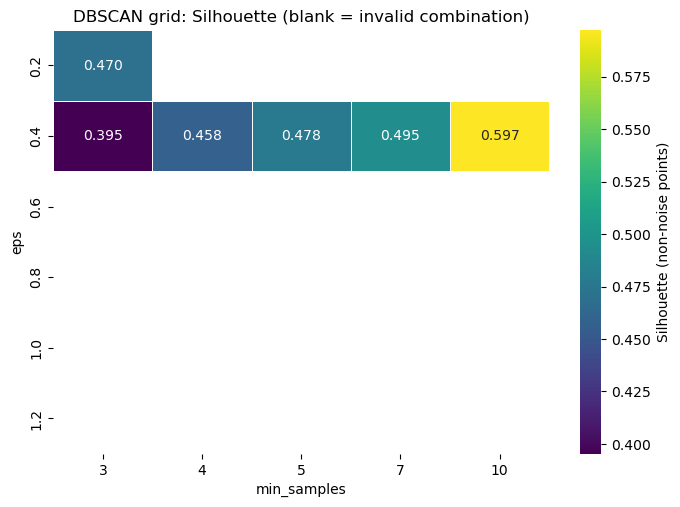

In [73]:
eps_list = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
ms_list = [3, 4, 5, 7, 10]
sil_grid = pd.DataFrame(np.nan, index=eps_list, columns=ms_list)
info = []
for e in eps_list:
    for m in ms_list:
        lab = DBSCAN(eps=e, min_samples=m).fit_predict(X_2d_scaled)
        ncl = len(set(lab)) - (1 if -1 in lab else 0)
        noise = (lab == -1).mean()
        valid = (ncl >= 2) and (noise < 0.30)
        s = silhouette_score(X_2d_scaled[lab != -1], lab[lab != -1]) if valid else np.nan
        sil_grid.loc[e, m] = s
        info.append({"eps": e, "min_samples": m, "clusters": ncl, "noise_%": round(noise * 100, 1),
                     "valid": valid, "silhouette": round(s, 4) if valid else np.nan})
grid_df = pd.DataFrame(info)
display(grid_df[grid_df["valid"]].sort_values("silhouette", ascending=False).reset_index(drop=True))

plt.figure(figsize=(8, 5.5))
sns.heatmap(sil_grid.astype(float), annot=True, fmt=".3f", cmap="viridis", linewidths=.5,
            cbar_kws={"label": "Silhouette (non-noise points)"}, mask=sil_grid.isna())
plt.xlabel("min_samples"); plt.ylabel("eps")
plt.title("DBSCAN grid: Silhouette (blank = invalid combination)")
plt.show()

In [75]:
valid = grid_df[grid_df["valid"]].copy()
best_row = valid.sort_values("silhouette", ascending=False).iloc[0]
print("Top-silhouette combination:\n", best_row.to_dict())
best_eps, best_ms = float(best_row["eps"]), int(best_row["min_samples"])

db_best = DBSCAN(eps=best_eps, min_samples=best_ms).fit(X_2d_scaled)
df["DBSCAN_Cluster"] = db_best.labels_
n_cl = len(set(db_best.labels_)) - (1 if -1 in db_best.labels_ else 0)
n_noise = int((db_best.labels_ == -1).sum())
print(f"\nFinal DBSCAN: eps={best_eps}, min_samples={best_ms} -> {n_cl} clusters, "
      f"{n_noise} noise points ({n_noise/len(df)*100:.1f}%)")

Top-silhouette combination:
 {'eps': 0.4, 'min_samples': 10, 'clusters': 4, 'noise_%': 25.5, 'valid': True, 'silhouette': 0.5972}

Final DBSCAN: eps=0.4, min_samples=10 -> 4 clusters, 51 noise points (25.5%)


# 5.4  Visualise & Profile DBSCAN Clusters

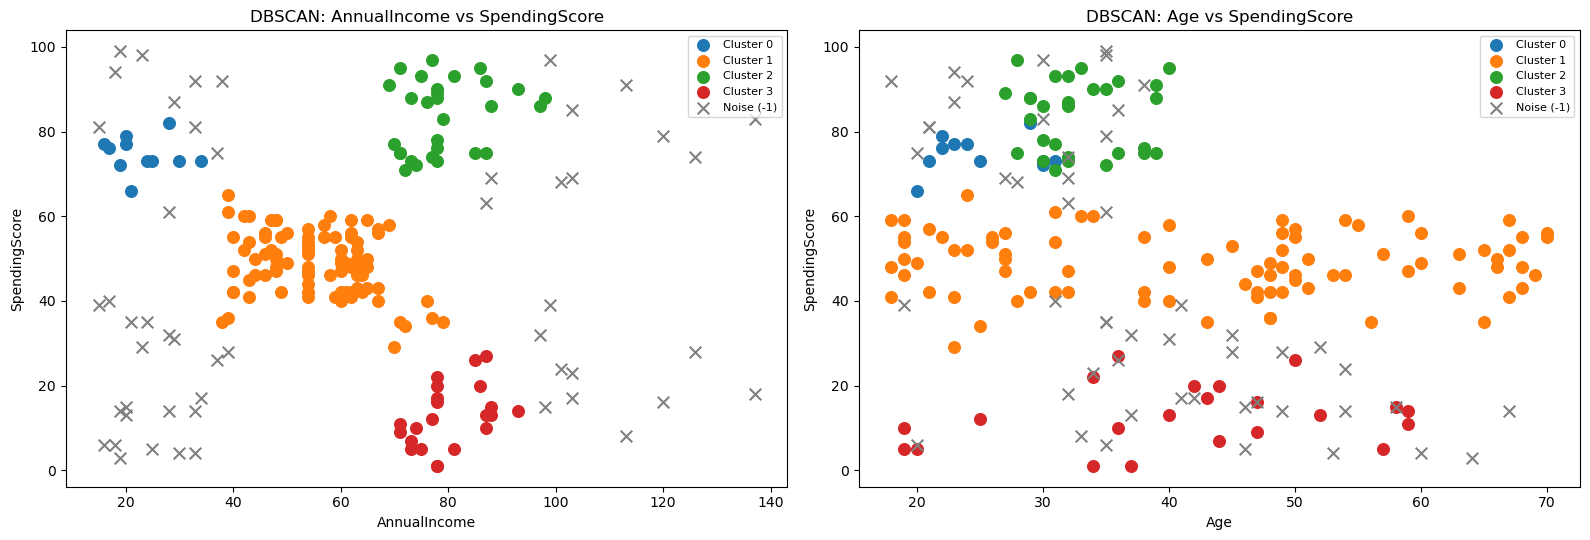

In [80]:
labels_db = df["DBSCAN_Cluster"].values
cl_ids = sorted(set(labels_db) - {-1})

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, xcol in zip(axes, ["AnnualIncome", "Age"]):
    for cid in cl_ids:
        m = labels_db == cid
        ax.scatter(df.loc[m, xcol], df.loc[m, "SpendingScore"], s=70, label=f"Cluster {cid}")
    m = labels_db == -1
    ax.scatter(df.loc[m, xcol], df.loc[m, "SpendingScore"], color="grey", marker="x", s=70, label="Noise (-1)")
    ax.set_xlabel(xcol); ax.set_ylabel("SpendingScore")
    ax.set_title(f"DBSCAN: {xcol} vs SpendingScore");
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [82]:
db_profile = profile_clusters(df, "DBSCAN_Cluster")
print("DBSCAN cluster profile (noise excluded), sorted by SpendingScore desc")
display(db_profile)

noise = df[df["DBSCAN_Cluster"] == -1]
print(f"\nNoise points: {len(noise)} ({len(noise)/len(df)*100:.1f}%)")
print("Noise mean profile:")
print(noise[["Age", "AnnualIncome", "SpendingScore"]].mean().round(1))
print("\nNoise gender split:", noise["Gender"].value_counts().to_dict())
print("Noise distance from overall data centre (scaled units): mean =",
      np.linalg.norm(X_2d_scaled[labels_db == -1], axis=1).mean().round(2),
      "| non-noise mean =", np.linalg.norm(X_2d_scaled[labels_db != -1], axis=1).mean().round(2))

DBSCAN cluster profile (noise excluded), sorted by SpendingScore desc


,Count,Age,AnnualIncome,SpendingScore,Persona
DBSCAN_Cluster,,,,,
2,29,32.9,79.2,83.6,Big Spenders
0,11,25.2,23.1,74.6,Young Aspirers
1,87,42.8,55.4,48.8,Mainstream Shoppers
3,22,41.0,80.2,12.7,Careful Spenders



Noise points: 51 (25.5%)
Noise mean profile:
Age              37.5
AnnualIncome     58.3
SpendingScore    44.5
dtype: float64

Noise gender split: {'Female': 30, 'Male': 21}
Noise distance from overall data centre (scaled units): mean = 1.98 | non-noise mean = 0.93


**Who are the noise shoppers?** The 51 noise points have a mean profile of **age 37.5, income 58.3k$, score 44.5** — i.e. very close to the average customer — not extreme outliers. Cross-tabulating with K-Means shows they are *boundary shoppers*: 21 of the 23 Budget Shoppers, 10 each from Young Aspirers, Careful Spenders and Big Spenders. With min_samples = 10, the small and loosely-packed **Budget Shoppers segment is dissolved almost completely into noise**, and the cluster boundaries are trimmed. So DBSCAN's noise here is not "weird shoppers" but "shoppers that sit between or at the edges of dense areas".

DBSCAN finds 4 personas (Big Spenders, Young Aspirers, Mainstream, Careful Spenders) — it **misses the Budget Shoppers segment**, which is commercially relevant.

# Step 6: Algorithm Comparison & Business Interpretation
# 6.1  Internal Metrics Comparison Table

In [85]:
km_lab = df["KMeans_Cluster"].values
ag_lab = df["Agg_Cluster"].values
db_lab = df["DBSCAN_Cluster"].values

rows = []
for name, params, lab in [
    ("K-Means", f"k={k_optimal}, init=k-means++, n_init=20", km_lab),
    ("Agglomerative", f"n_clusters={n_chosen}, linkage={best_link}", ag_lab),
    ("DBSCAN", f"eps={best_eps}, min_samples={best_ms}", db_lab),
]:
    s, d, c = internal_metrics(X_2d_scaled, lab)
    rows.append({"Algorithm": name, "Hyperparameters": params,
                 "Clusters": len(set(lab) - {-1}),
                 "Silhouette (up)": round(s, 4), "Davies-Bouldin (down)": round(d, 4),
                 "Calinski-Harabasz (up)": round(c, 1),
                 "Noise %": round((lab == -1).mean() * 100, 1)})
metrics_df = pd.DataFrame(rows).set_index("Algorithm")
display(metrics_df)


,Hyperparameters,Clusters,Silhouette (up),Davies-Bouldin (down),Calinski-Harabasz (up),Noise %
Algorithm,,,,,,
K-Means,"k=5, init=k-means++, n_init=20",5,0.5547,0.5722,248.6,0.0
Agglomerative,"n_clusters=5, linkage=ward",5,0.5538,0.5779,244.4,0.0
DBSCAN,"eps=0.4, min_samples=10",4,0.5972,0.4734,263.6,25.5


# 6.2  Cluster Stability Check for K-Means

In [87]:
seeds = [0, 7, 21, 42, 99]
stab = []
for sd in seeds:
    km = KMeans(n_clusters=k_optimal, init="k-means++", n_init=10, random_state=sd).fit(X_2d_scaled)
    stab.append({"random_state": sd, "Silhouette": silhouette_score(X_2d_scaled, km.labels_), "Inertia": km.inertia_})
stab_df = pd.DataFrame(stab).round(5)
display(stab_df)
print(f"Silhouette mean +/- std over 5 runs: {stab_df['Silhouette'].mean():.4f} +/- {stab_df['Silhouette'].std(ddof=0):.6f}")

C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\MAYUR MAKVANA\AppData\Roaming\Python\Python312

,random_state,Silhouette,Inertia
0,0,0.55466,65.56841
1,7,0.55466,65.56841
2,21,0.55466,65.56841
3,42,0.55466,65.56841
4,99,0.55466,65.56841


Silhouette mean +/- std over 5 runs: 0.5547 +/- 0.000000


**Stability:** Silhouette = **0.5547 ± 0.0000** across the five seeds (identical inertia 65.57 each time). K-Means is perfectly stable here because the five groups are compact and well separated, and `k-means++` with `n_init=10` finds the same global optimum from every initialisation.

# 6.3  Business Recommendation

## 6.3 Business Recommendation

**To:** Retail Operations Director, Nexus Malls / Phoenix Marketcity  
**Re:** Shopper segmentation — recommended approach and actions

**Recommended algorithm: K-Means (k = 5) on Annual Income and Spending Score.**
K-Means achieves Silhouette **0.555**, Davies-Bouldin **0.572** and Calinski-Harabasz **248.6**; it is perfectly reproducible (±0.0000 over 5 seeds), assigns **every** customer to a segment, and — unlike Ward or DBSCAN — can score *new* shoppers through `predict()`, which is needed for the mall app. Ward hierarchical clustering agrees on 98% of customers (so the segments are robust), and DBSCAN's higher raw scores (0.597 Silhouette) come at the cost of labelling 25.5% of shoppers as noise and losing the Budget Shopper segment, so we do not recommend it for operational targeting.

**Segments and one concrete action each**

| Segment (share) | Description | Strategy |
|---|---|---|
| **Big Spenders** (19.5%) | Avg. age 33, ₹86k income, score 82 | Premium lounge with curated luxury pop-ups next to the food court; early-access invitations for new luxury launches. |
| **Careful Spenders** (17.5%) | Avg. age 41, high income 88k, score only 17 | Run experiential "try before you buy" events and personal-shopper appointments; send quality-led, not discount-led, offers via the app to raise their visit value. |
| **Young Aspirers** (11%) | Avg. age 25, low income, score 79 | Trend/fast-fashion zone near entrances and cinema; student-ID, EMI/BNPL and flash-sale offers, plus social-media contests. |
| **Mainstream Shoppers** (40.5%) | Avg. age 43, mid income, average spending | Westside/Lifestyle-type brands in the central atrium; points-based loyalty programme and seasonal-sale campaigns, since this largest group drives volume. |
| **Budget Shoppers** (11.5%) | Avg. age 45, low income, score 21 | Value-for-money stores and supermarkets near mall entrances; ₹50-off coupons through the mall app and BOGO weekends. |

**Additional data that would improve segmentation:** purchase categories and basket sizes, visit frequency and dwell time from footfall sensors, loyalty-app behaviour (coupon redemption, browsing), actual income/spend in ₹ instead of a relative score, and household composition. With richer behaviour data, the extra dimensions (Age, Gender) could become useful, which they are not on the current dataset (5D Silhouette 0.314 vs 0.555).

# Step 7: Pipeline, Deployment & GitHub Submission
# 7.1  Save the Final Clustering Pipeline

In [90]:
# Best model: K-Means (2D). Fitted on scaled Income + SpendingScore.
best_model = kmeans_2d
scaler = scaler_2d
joblib.dump(scaler, "mall_scaler.pkl")
joblib.dump(best_model, "mall_segmentation_model.pkl")
print("Saved mall_scaler.pkl and mall_segmentation_model.pkl")

# Reload to prove the pipeline works from disk
scaler_loaded = joblib.load("mall_scaler.pkl")
model_loaded = joblib.load("mall_segmentation_model.pkl")

def classify_shopper(age, annual_income, spending_score, gender=None,
                     scaler=scaler_loaded, model=model_loaded):
    """Return (cluster_label, persona) for a new shopper.
    annual_income is in k$ (dataset units), spending_score is 1-100.
    The saved 2D model segments on income + spending; age and gender are accepted for
    logging / future 5D models but do not change the cluster."""
    new = pd.DataFrame([[annual_income, spending_score]], columns=["AnnualIncome", "SpendingScore"])
    label = int(model.predict(scaler.transform(new))[0])
    centre = scaler.inverse_transform(model.cluster_centers_)[label]
    return label, persona_from_profile(centre[0], centre[1])

tests = [
    (22, "Female", 30, 85), (45, "Male", 90, 15), (35, "Female", 85, 88),
    (50, "Male", 20, 10), (30, "Female", 55, 50),
]
out = []
for age, g, inc, sp in tests:
    lab, per = classify_shopper(age, inc, sp, g)
    out.append({"Age": age, "Gender": g, "AnnualIncome(k$)": inc, "SpendingScore": sp,
                "Cluster": lab, "Persona": per})
pd.DataFrame(out)

Saved mall_scaler.pkl and mall_segmentation_model.pkl


,Age,Gender,AnnualIncome(k$),SpendingScore,Cluster,Persona
0,22,Female,30,85,2,Young Aspirers
1,45,Male,90,15,3,Careful Spenders
2,35,Female,85,88,1,Big Spenders
3,50,Male,20,10,4,Budget Shoppers
4,30,Female,55,50,0,Mainstream Shoppers
